In [14]:
import numpy as np
import matplotlib.pyplot as plt

In [6]:
class Layer:
    def __init__(self):
        return

    def forward_pass(self,x):
        return

    def backward_pass(self, derivative):
        return

    def update(self, derivative):
        return

In [7]:
#Standard relu as a layer, does not need to know params, will use X to map out gradient then apply it to incoming derivatives
class Relu(Layer):
    def __init__(self):
        super().__init__()
        self.x = None
        self.gradient = None

    def forward_pass(self,x):
        self.gradient = np.where(x > 0, 1, 0)
        self.x = x
        return self.x * self.gradient

    def backward_pass(self, derivative):
        return derivative * self.gradient

In [8]:
#Class for leaky ReLU, does not need to know params, will use X to map out gradient then apply it to incoming derivatives
class LeakyRelu(Layer):
    def __init__(self, alpha=0.01):
        super().__init__()
        self.x = None
        self.gradient = None
        self.alpha = alpha
    def forward_pass(self,x):
        self.gradient = np.where(x > 0, 1, self.alpha)
        self.x = x
        return self.x * self.gradient
    def backward_pass(self, derivative):
        return derivative * self.gradient

In [9]:
class Linear(Layer):
    def __init__(self,input_dim,output_dim,learning_rate=0.001,weights=None,biases=None):
        super().__init__()

        if weights is None:
            weights = np.random.uniform(-1,1,size=(output_dim,input_dim))
        if biases is None:
            biases = np.random.uniform(-1,1,size=(output_dim,1))

        self.learning_rate = learning_rate
        self.x = None
        self.weights = weights
        self.biases = biases
        self.input_dim = input_dim
        self.output_dim = output_dim

    def forward_pass(self,x):
        self.x = x
        return self.weights @ x + self.biases

    def backward_pass(self, derivative):
        return self.weights.T @ derivative

    def update(self, derivative):
        weight_gradient = derivative @ self.x.T
        bias_gradient = np.mean(derivative, axis=1,keepdims=True)

        self.weights -= self.learning_rate * weight_gradient
        self.biases -= self.learning_rate * bias_gradient

In [10]:
class Model:
    def __init__(self, layers):
        self.layers = layers

    def forward_pass(self,x):
        inp = x
        for i in self.layers:
            inp = i.forward_pass(inp)
        return inp

    def backward_pass(self, derivative):
        gradient = derivative
        for i in reversed(self.layers):
            temp_gradient = i.backward_pass(gradient)
            i.update(gradient)
            gradient = temp_gradient

    def train(self,x,y,iterations=10000,cutoff = 0.001):
        cost_history = []
        for i in range(iterations):
            prediction = self.forward_pass(x)
            loss = prediction - y
            cost_history.append(np.average(loss**2)/2)
            self.backward_pass(loss)
            if len(cost_history) < 2:
                continue
            if abs((cost_history[-1]-cost_history[-2])/cost_history[-1]) < cutoff:
                break
        return cost_history

In [39]:
#Funct to plot points
def plot_3d(x1,x2,y):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(x1,x2,y)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("y")
    plt.show()

def plot_2d(x,name):
    plt.plot(x,'o',label=name)
    plt.legend()
    plt.show()
# Function to plot two sets of points
def plot_comparison_3d(x1, x2, y1, x3, x4, y2):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(x1, x2, y1, color="blue", label="Set 1")
    ax.scatter(x3, x4, y2, color="orange", label="Set 2")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("y")
    ax.legend()
    plt.show()

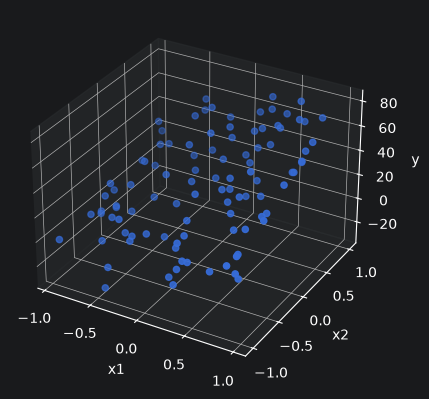

In [27]:
#Training data:
batch_size = 100
input_size = 2
output_size = 1
scale = 1
deviation = 10 #%
w = np.array([20,30])
b = 30
x_input = np.random.uniform(-scale,scale,size=(input_size,100))
y_output = w @ x_input + b + np.random.normal(0,scale*deviation,size=(output_size,100))

#plotting training data
plot_3d(*x_input,y_output)

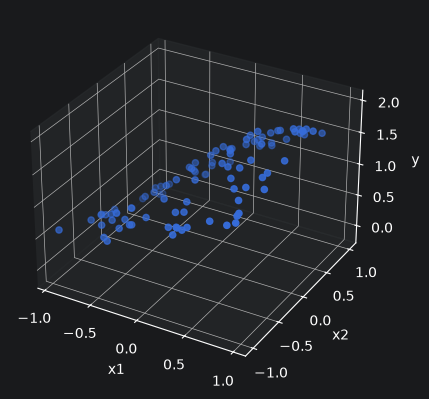

[np.float64(678.0853915356624), np.float64(659.1220050198752), np.float64(637.7133526821424), np.float64(612.5264993880664), np.float64(582.6407974168117), np.float64(547.3568181317568), np.float64(506.507249411994), np.float64(460.1213468346672), np.float64(409.0509724584223), np.float64(355.9241024559785), np.float64(303.1493135780377), np.float64(254.16156681633072), np.float64(211.9991641856057), np.float64(178.24363431985162), np.float64(153.36406839363545), np.float64(136.18135936538255), np.float64(124.7807134312176), np.float64(117.4778840897674), np.float64(112.94051614924194), np.float64(109.9162945802485), np.float64(107.8596434855487), np.float64(106.31525930126023), np.float64(105.06621594014273), np.float64(103.9796974940582), np.float64(102.9879915037066)]


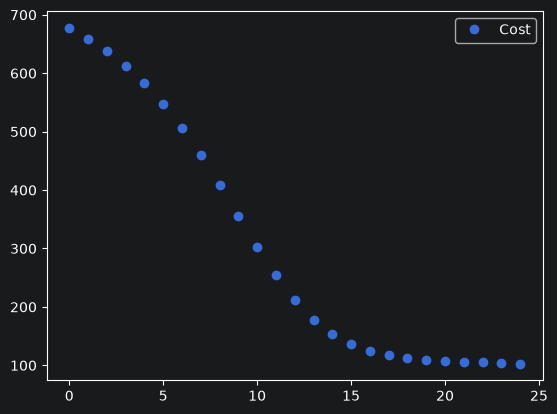

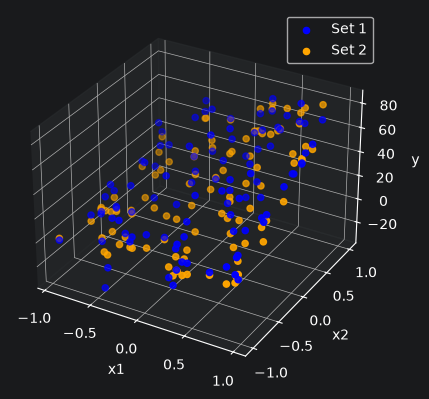

In [41]:
model = Model([
    Linear(input_dim=2,output_dim=10,learning_rate=0.0001),
    LeakyRelu(alpha=0.01),
    Linear(input_dim=10,output_dim=1,learning_rate=0.0001)
])
#prediction graph:
y_hat = model.forward_pass(x_input)
plot_3d(*x_input,y_hat)

cost_history = model.train(x_input,y_output,iterations=10000,cutoff=0.01)
print(cost_history)
#Trained graph:
y_hat = model.forward_pass(x_input)
plot_2d(cost_history,"Cost")
plot_comparison_3d(*x_input,y_output,*x_input,y_hat)